# STAT6-DNA complex 5D39 with `synced_structure`

Human STAT6 bound to DNA (X-ray, 3.2 Å). The asymmetric unit holds two STAT6 dimers (protein chains A, C and B, D), each bound to a 21-bp DNA duplex (strands N, M and E, F).
This notebook loads it from RCSB, summarizes the chains, measures the chain interfaces, and draws contact maps and a 3D view.

Requires network access and the package installed: `pip install -e .` from the repository root.

In [1]:
from synced_structure import SyncedStructure

stat6 = SyncedStructure.from_rcsb("5D39")
stat6.summary()

[PYTHON-INFO] 2026-10-21 18:37:54 | Loaded RCSB structure 5D39 | execution time: 1.43s | max memory: 212.4 MB


,chain_id,auth_chain_id,entity_id,description,external_ref,refseq_id,sequence_length,reference_length,mapped_residues,mapping_fraction
0,A,A,1,Signal transducer and activator of transcripti...,P42226,P42226,489,539,489,1.0
1,B,B,1,Signal transducer and activator of transcripti...,P42226,P42226,484,539,484,1.0
2,C,C,1,Signal transducer and activator of transcripti...,P42226,P42226,484,539,484,1.0
3,D,D,1,Signal transducer and activator of transcripti...,P42226,P42226,487,539,487,1.0
4,E,N,2,DNA (5'-D(P*TP*CP*TP*GP*TP*CP*TP*TP*CP*CP*AP*G...,5D39,5D39,21,21,21,1.0
5,F,M,3,DNA (5'-D(P*AP*TP*GP*GP*AP*TP*TP*TP*CP*CP*TP*G...,5D39,5D39,21,21,21,1.0
6,G,E,3,DNA (5'-D(P*AP*TP*GP*GP*AP*TP*TP*TP*CP*CP*TP*G...,5D39,5D39,21,21,21,1.0
7,H,F,2,DNA (5'-D(P*TP*CP*TP*GP*TP*CP*TP*TP*CP*CP*AP*G...,5D39,5D39,21,21,21,1.0


Biomolecule content per chain: four protein chains, four DNA strands, and water.

In [2]:
stat6.moiety_summary.pivot_table(index="chain_id", columns="moiety", values="residues", fill_value=0).astype(int)

moiety,nucleic,protein,water
chain_id,,,
A,0,489,61
B,0,484,55
C,0,484,50
D,0,487,31
E,21,0,4
F,21,0,2
G,21,0,1
H,21,0,2


## Interfaces

Chains in contact, then buried surface area and heavy-atom contacts for every pair in contact. Within each complex, the two STAT6 chains form the dimer and both touch the two DNA strands; the A-B contact links the two complexes in the crystal.

In [3]:
partners = stat6.chain_contact_partners()
partners

{'A': ['B', 'C', 'M', 'N'],
 'B': ['A', 'D', 'E', 'F'],
 'C': ['A', 'M', 'N'],
 'D': ['B', 'E', 'F'],
 'N': ['A', 'C', 'M'],
 'M': ['A', 'C', 'N'],
 'E': ['B', 'D', 'F'],
 'F': ['B', 'D', 'E']}

In [4]:
pairs = sorted({tuple(sorted((a, b))) for a, chains in partners.items() for b in chains})
stat6.interface_all(pairs)["complex"][["auth_chain_a", "auth_chain_b", "dASA_A2", "n_contacts", "min_dist_A"]]

pairs:   0%|          | 0/13 [00:00<?, ?pair/s]

pairs:   8%|▊         | 1/13 [00:04<00:52,  4.38s/pair]

pairs:  15%|█▌        | 2/13 [00:07<00:42,  3.83s/pair]

pairs:  23%|██▎       | 3/13 [00:08<00:25,  2.52s/pair]

pairs:  31%|███       | 4/13 [00:09<00:17,  1.91s/pair]

...

pairs:  77%|███████▋  | 10/13 [00:18<00:03,  1.17s/pair]

pairs:  85%|████████▍ | 11/13 [00:18<00:02,  1.09s/pair]

pairs:  92%|█████████▏| 12/13 [00:19<00:00,  1.24pair/s]

pairs: 100%|██████████| 13/13 [00:19<00:00,  1.63pair/s]

,auth_chain_a,auth_chain_b,dASA_A2,n_contacts,min_dist_A
0,A,B,1079.48,175,2.644
1,A,C,2416.32,390,2.388
2,A,M,563.29,45,2.969
3,A,N,596.74,72,2.717
4,B,D,2469.27,408,1.848
5,B,E,510.24,44,2.521
6,B,F,544.17,66,2.610
7,C,M,578.54,75,2.925
8,C,N,455.89,51,2.654
9,D,E,594.23,80,2.485


## Contact maps

The STAT6 dimer of one complex on a block map: intra-chain contacts in gray, the A-C interface in color.

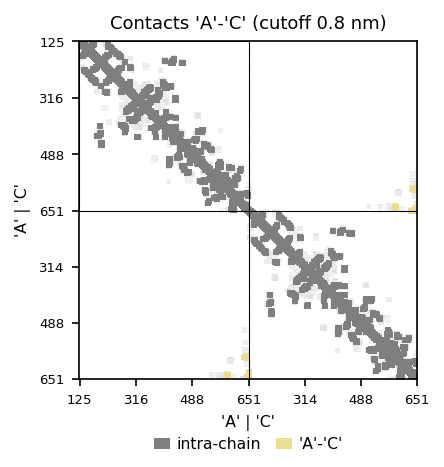

In [5]:
fig, ax = stat6.plot_contacts_multi(("A", "C"), show_color_legend=True)

The DNA duplex bound by that dimer. At the default 0.8 nm cutoff only a few base steps are colored, so this map uses 1.2 nm. Base pairing between strands N and M shows as an anti-diagonal along the whole duplex.

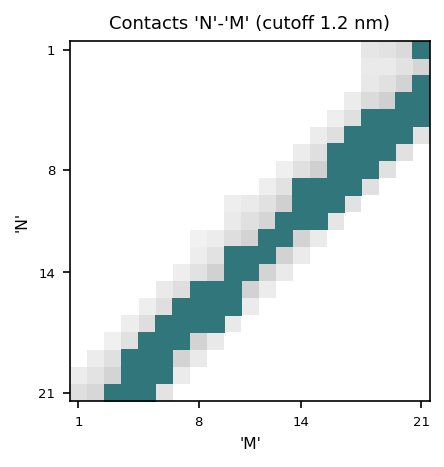

In [6]:
fig, ax = stat6.plot_contact_map("N", "M", cutoff=1.2)

## Protein-DNA interface

The DNA strands are 21 nt against about 490 STAT6 residues, so this interface reads better as a table: the STAT6 residues of chain A that bury the most surface against strand N.

In [7]:
residues = stat6.interface("A", "N")["residues"]
residues[residues["auth_chain"] == "A"].nlargest(10, "dSASA_A2")[["resid", "resname", "dSASA_A2", "min_dist_A", "partners"]]

,resid,resname,dSASA_A2,min_dist_A,partners
4,414,VAL,59.84,3.112,E7 DT;E8 DT
5,415,HIS,43.13,3.640,E7 DT;E8 DT;E9 DC
3,379,VAL,36.75,2.717,E6 DC;E7 DT
6,417,ASN,29.42,3.027,E7 DT
7,418,GLN,26.47,2.960,E6 DC;E7 DT
0,367,LYS,25.15,3.082,E8 DT
2,378,SER,24.25,3.676,E6 DC
1,370,ARG,17.66,2.950,E6 DC;E7 DT


## 3D view

Click an atom to label it.

In [8]:
stat6.show_structure_3d(title="STAT6-DNA complex 5D39")

[PYTHON-INFO] 2026-10-21 18:38:16 | Rendered view of 5D39 at angles (0, 0, 0) | execution time: 1.15s | max memory: 552.8 MB
